# MVO4 sweep notebook

This notebook does three things:

1. **Walks through one MVO4 run step by step**, in the same order and with the same section names as `New Training Docs/MVODB/mvo4.ipynb` (preselection, download + injection, MVO statistics, optimization, evaluation). Each section says which cells of the original notebook it reproduces.
2. **Proves the sweep engine matches the original notebook's code** (section 6). It runs the notebook's own cells, copied verbatim into `reference/mvo4_notebook_reference.py`, next to the engine on the same data and compares every intermediate result.
3. **Runs a sweep and shows the results** (sections 7-8).

All settings (grid, event dates, model settings) live in `config.py`. See `README.md` for the full explanation. Run the cells top to bottom; with the cache shipped in `cache/`, sections 0-5 take seconds and section 6 takes about a minute per event.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
HERE = Path.cwd()
sys.path.insert(0, str(HERE)); sys.path.insert(0, str(HERE / "reference"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
import mvo4_engine as E

pd.set_option("display.max_columns", 50, "display.width", 200)
E.environment()

{'python': '3.13.14',
 'pandas': '2.3.3',
 'numpy': '2.2.3',
 'scikit_learn': '1.7.2',
 'pypfopt': '1.6.0',
 'yfinance': '1.3.0'}

## 0. Pick one run  *(mvo4.ipynb cell `d54d1018`)*

Choose an event from `config.EVENTS` and one parameter combination. `K`, `Seeds`, `MinAppear`, `w1` are the notebook's `N`, `Seeds`, `Min_appear`, `w1`. The defaults below are the original notebook's own settings.

In [2]:
EVENT = "Swan 9"                          # "Swan 8", "Swan 9", "Swan 10D", "Swan 11A", or any event you add to config.py
K, Seeds, MinAppear, w1 = 7, 5, 3, 0.17

ev = C.EVENTS[EVENT]
start, end, extended = E.training_window(EVENT)
print(f"{EVENT}: training window {start.date()} -> {end.date()} (end = Friday before the peak's week)"
      f"{'  (start moved earlier so the crash curve fits)' if extended else ''}")
print(f"crash curve: T1_METHOD = {C.T1_METHOD!r}, t1/t2/dd = {E.curve_params(ev['train_swans'])}")
print(f"evaluated {ev['peak']} (peak) -> {ev['bottom']} (bottom)")
print(f"training swans (beta): {ev['train_swans']}    R_fwd file: {ev['optdata']}")

Swan 9: training window 2018-12-30 -> 2020-02-14 (end = Friday before the peak's week)
crash curve: T1_METHOD = 'average', t1/t2/dd = (72, 200, 0.24709028449533582)
evaluated 2020-02-19 (peak) -> 2020-03-23 (bottom)
training swans (beta): ['Swan4', 'Swan5', 'Swan6', 'Swan7', 'Swan8']    R_fwd file: revised_swan9_sp100_optdata4.xlsx


## 1. Preselection  *(cells `a1c7e6cb` – `9acaecb3`, method `K_means_multiple`)*

K-means is fitted on each stock's beta in the five training swans, once for every seed from 1 to 1,000, and the seeds are ranked by Davies-Bouldin score (lower means cleaner clusters). The best `Seeds` seeds each vote for the stocks in their lowest-beta cluster; if that cluster has fewer than 10 stocks, the next-lowest cluster is added. Stocks with at least `MinAppear` votes (among the 22 most-voted) go to MVO. Each kept stock's `avg` is its mean beta over the training swans, which scales how hard the crash injection hits it (this is the corrected cell `7335a9dc`).

In [3]:
ranking = E.dbi_ranking(ev["train_swans"], K)
print("best DBI seeds:", [s for s, _ in ranking[:Seeds]])
pre, votes = E.preselect(ev["train_swans"], K, Seeds, MinAppear, return_votes=True)
print(f"votes per stock (out of {Seeds}):")
display(votes.to_frame().T)
print(f"{len(pre)} stocks preselected:")
pre

best DBI seeds: [335, 299, 969, 609, 442]


votes per stock (out of 5):


,ABT,CL,EXC,JNJ,KO,LLY,MDLZ,MRK,NEE,PEP,PG,SBUX,SO,VZ,WMT,AMGN,AMZN,COST,MO,PFE
votes,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,3,3,3,3,3


20 stocks preselected:


,Swan4,Swan5,Swan6,Swan7,Swan8,avg
Ticker,,,,,,
ABT,0.702188,0.474696,0.311079,1.073150,0.431921,0.598607
AMGN,0.795355,0.502892,0.109292,0.843475,0.659977,0.582198
AMZN,-0.445606,0.328167,0.123350,0.334033,1.561997,0.380388
CL,0.099788,0.617542,-0.045657,0.784583,0.569564,0.405164
COST,0.829818,0.976294,-0.015790,0.618966,0.918643,0.665586
EXC,0.519667,0.794675,0.263389,0.605246,-0.123438,0.411908
JNJ,0.403161,0.739963,0.360346,0.668742,0.555245,0.545491
KO,-0.170562,0.536675,0.325968,0.614677,-0.049526,0.251446
LLY,0.746268,0.920577,0.280671,0.780342,0.061466,0.557865


## 2. Training prices and crash injection  *(cells `2bd97cf4` – `3be4c870`)*

Real daily closes for the preselected stocks over the training window, multiplied by `1 - avg_beta x market_drop`. The market-drop curve ramps up to `dd` over `t1` trading days, recovers over `t2` days and is zero after that. `t1`, `t2` and `dd` are averages from `MarketDD.xlsx` over every swan from Swan1 to the last training swan, matching the Black Swan Signatures workbook's rows 69–75. The notebook's own executed `t1` is correlation-weighted instead; set `C.T1_METHOD = "weighted"` to use that.

The training window ends the Friday before the swan's week and starts 13.5 months earlier, moved back only if it can't hold all `t1 + t2` days.

t1=72  t2=200  dd=24.71%  |  284 trading days in the window  |  curve cut off: False


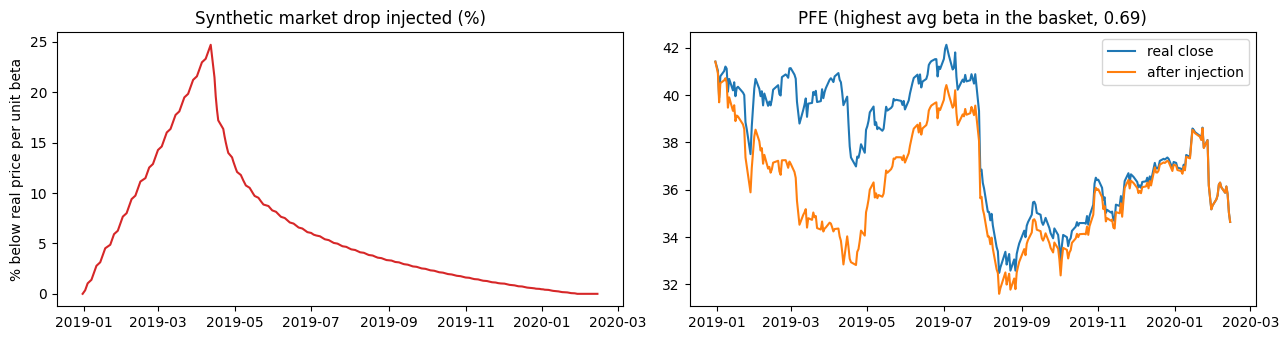

In [4]:
ri = E.risk_inputs(EVENT, pre)
print(f"t1={ri['t1']}  t2={ri['t2']}  dd={ri['dd']:.2%}  |  {ri['total_day']} trading days in the window  |  curve cut off: {ri['curve_truncated']}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(ri["raw_prices"].index, ri["curve"] * 100, color="tab:red")
ax[0].set_title("Synthetic market drop injected (%)"); ax[0].set_ylabel("% below real price per unit beta")
tk = pre["avg"].loc[ri["raw_prices"].columns].idxmax()
ax[1].plot(ri["raw_prices"][tk], label="real close")
ax[1].plot(ri["injected_prices"][tk], label="after injection")
ax[1].set_title(f"{tk} (highest avg beta in the basket, {pre.loc[tk, 'avg']:.2f})"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. MVO statistics  *(cells `668e84bf` – `3fea5d8b`)*

Computed from the **injected** prices, over the last 365 days of the training window only: each stock's max drawdown (`fall`), the weekly-return covariance x 51, and `E_2 = R_fwd_30_MA / fall`, where `R_fwd_30_MA` is the forward-return estimate from the event's optdata file.

In [5]:
print(f"statistics use {ri['one_year_ago_date'].date()} -> {ri['train_end'].date()}")
pd.DataFrame({"avg beta": pre.loc[ri["E_2"].index, "avg"], "R_fwd_30_MA": ri["R_fwd"],
              "fall (max drawdown)": ri["fall"], "E_2": ri["E_2"]}).sort_values("E_2", ascending=False).round(4)

statistics use 2019-02-14 -> 2020-02-14


,avg beta,R_fwd_30_MA,fall (max drawdown),E_2
Symbol,,,,
AMZN,0.3804,0.2349,0.1460,1.6087
WMT,0.5359,0.1135,0.1080,1.0511
COST,0.6656,0.0580,0.0607,0.9550
MDLZ,0.3365,0.0760,0.0821,0.9262
MRK,0.6050,0.0965,0.1216,0.7937
ABT,0.5986,0.0667,0.1008,0.6617
EXC,0.4119,0.0670,0.1163,0.5759
AMGN,0.5822,0.0555,0.1080,0.5144
JNJ,0.5455,0.0496,0.1036,0.4785


## 4. Optimization  *(cells `b876261e`, `4e90df30`)*

`EfficientFrontier(E_2/100, cov, weight_bounds=(0, w1)).max_sharpe(0.0)`. There is no fallback to another rf or objective. Weights below 3% are dropped and the rest renormalized.

In [6]:
w = E.optimize(ri["E_2"], ri["cov"], w1)
if w is None:
    print("optimizer failed for this combination (it would be recorded as opt_failed in a sweep)")
else:
    display(w.sort_values(ascending=False).to_frame("weight").style.format("{:.2%}"))

,weight
AMZN,17.31%
COST,17.31%
MDLZ,17.31%
WMT,17.31%
MRK,17.31%
LLY,7.07%
MO,6.38%


## 5. Evaluation  *(cells `11a8c553` – `b45e8a54`)*

The basket is bought at the close on `buy_date` (default: the peak date) and its drop is measured from the peak close to the bottom close, using **real** prices (the injection only ever touches the training statistics). Protection Ratio = 1 − portfolio drop / index drop.

For Swan 9, the second line reruns everything with the original notebook's own settings: weighted `t1`, its training dates, and buying one trading day before the peak. It reproduces the notebook's printed PR of 0.4882206644308368.

In [7]:
res = E.evaluate(EVENT, w)
print(f"bought {ev.get('buy_date', ev['peak'])}: portfolio drop {res['port_dd']:.2%}   {C.BENCHMARK} drop {res['mkt_dd']:.2%}   ->   PR = {res['PR']:.4%}")

if EVENT == "Swan 9":
    # mvo4.ipynb's own settings: weighted t1, its dates (end 2020-02-15 = through 2020-02-14),
    # and buying at the 2020-02-18 close, run with the notebook's K=7, Seeds=5, MinAppear=3, w1=0.17
    saved = (C.T1_METHOD, dict(C.EVENTS[EVENT]))
    C.T1_METHOD = "weighted"
    C.EVENTS[EVENT].update(train_start="2019-01-01", train_end="2020-02-15", buy_date="2020-02-18")
    r = E.run_one(EVENT, 7, 5, 3, 0.17)
    print(f"with mvo4.ipynb's own settings:  PR = {r['PR']!r}   (the notebook printed 0.4882206644308368)")
    C.T1_METHOD, C.EVENTS[EVENT] = saved[0], saved[1]

bought 2020-02-19: portfolio drop 16.04%   ^OEX drop 31.53%   ->   PR = 49.1195%


with mvo4.ipynb's own settings:  PR = np.float64(0.4882206644308362)   (the notebook printed 0.4882206644308368)


## 6. Parity check: sweep engine vs. the original notebook's code

`reference/mvo4_notebook_reference.py` is the original notebook's cells copied verbatim (each block is labeled with its cell id), wrapped in one function. The only changes are five marked `# ADAPTED`, listed at the top of that file and in the README: prices come from the same cache instead of `yf.download`, the cell-`7335a9dc` look-ahead bug is replaced by the notebook's own commented-out fix, the beta table is passed with the swans in chronological order, inputs are arguments, and two positional lookups use `.iloc`.

The notebook's executed `t1` line is the correlation-weighted one, so the check runs the engine with `T1_METHOD = "weighted"`, on the same training windows, data files and prices as the reference. For each event the cell below runs both on identical inputs and compares the 1,000-seed DBI ranking, the preselected stocks, the crash curve, the drawdowns, `E_2`, the covariance matrix, the weights and the PR. The notebook code recomputes the whole DBI ranking each time, so this takes about a minute per event. The same check runs from the command line with `python parity_check.py`.

In [8]:
import parity_check
PARITY_EVENTS = C.EVENTS_TO_RUN                       # e.g. ["Swan 9"] for a faster check
parity = parity_check.run(PARITY_EVENTS, K=7, Seeds=5, MinAppear=3, w1=0.17)
print("\nRESULT:", "every check matches" if parity.match.all() else f"{(~parity.match).sum()} check(s) differ")
with pd.option_context("display.max_colwidth", 70):
    display(parity)

Swan 8: ALL MATCH (63s)


Swan 9: ALL MATCH (64s)


Swan 10D: ALL MATCH (57s)


Swan 11A: ALL MATCH (71s)



RESULT: every check matches


,event,check,engine,notebook,match
0,Swan 8,"DBI seed ranking (all 1,000)","top 5: [541, 880, 408, 295, 794]","top 5: [541, 880, 408, 295, 794]",True
1,Swan 8,preselected stocks,"20: AMZN, BRK-B, CL, DUK, EXC, JNJ, KO, LLY, LMT, LOW, MDT, MO, NE...","20: AMZN, BRK-B, CL, DUK, EXC, JNJ, KO, LLY, LMT, LOW, MDT, MO, NE...",True
2,Swan 8,crash curve t1 / t2 / dd,73 / 216 / 0.253876,73 / 216 / 0.253876,True
3,Swan 8,training days in window,289,289,True
4,Swan 8,max drawdown per stock (fall),20 stocks,max |diff| 0.00e+00,True
5,Swan 8,E_2 = R_fwd / fall,20 stocks,max |diff| 0.00e+00,True
6,Swan 8,covariance matrix,20x20,max |diff| 0.00e+00,True
7,Swan 8,final weights,"LMT 17.0%, SPG 17.0%, KO 17.0%, AMZN 13.3%, NEE 12.1%, BRK-B 8.2%,...","LMT 17.0%, SPG 17.0%, KO 17.0%, AMZN 13.3%, NEE 12.1%, BRK-B 8.2%,...",True
8,Swan 8,PR,41.070586%,41.070586%,True
9,Swan 9,"DBI seed ranking (all 1,000)","top 5: [335, 299, 969, 609, 442]","top 5: [335, 299, 969, 609, 442]",True


## 7. Run a sweep

`run_sweep` runs every combination in `grid` on every event and returns one row per run. The tiny grid below runs in seconds so you can see the output format; set `grid = C.GRID` for the full 5,376-run sweep (about 10 minutes with the shipped cache). From a terminal, `python run_sweep.py` does the same and also writes `summary.xlsx`.

In [9]:
grid = dict(K=[6, 7], Seeds=[3], MinAppear=[3], w1=[0.13, 0.17])   # or: grid = C.GRID
SAVE_TO = None                                                     # or: HERE / "results" / "from_notebook"

if SAVE_TO: Path(SAVE_TO).mkdir(parents=True, exist_ok=True)
raw_small = E.run_sweep(grid, C.EVENTS_TO_RUN, SAVE_TO)
raw_small[["event", "K", "Seeds", "MinAppear", "w1", "status", "PR", "n_preselect", "n_final", "holdings"]]

  finished 16 runs in 2s; 16 solved


,event,K,Seeds,MinAppear,w1,status,PR,n_preselect,n_final,holdings
0,Swan 8,6,3,3,0.13,ok,0.463436,17,10,"{""AMZN"": 0.130001, ""BRK-B"": 0.130001, ""DUK"": 0..."
1,Swan 8,6,3,3,0.17,ok,0.474626,17,9,"{""AMZN"": 0.108299, ""BRK-B"": 0.164268, ""DUK"": 0..."
2,Swan 8,7,3,3,0.13,ok,0.644236,15,9,"{""AMZN"": 0.13, ""DUK"": 0.13, ""EXC"": 0.13, ""KO"":..."
3,Swan 8,7,3,3,0.17,ok,0.531486,15,7,"{""AMZN"": 0.175527, ""DUK"": 0.118068, ""EXC"": 0.0..."
4,Swan 9,6,3,3,0.13,ok,0.356393,20,9,"{""ABT"": 0.050932, ""AMZN"": 0.13132, ""COST"": 0.1..."
5,Swan 9,6,3,3,0.17,ok,0.491195,20,7,"{""AMZN"": 0.173111, ""COST"": 0.173111, ""LLY"": 0...."
6,Swan 9,7,3,3,0.13,ok,0.356393,20,9,"{""ABT"": 0.050932, ""AMZN"": 0.13132, ""COST"": 0.1..."
7,Swan 9,7,3,3,0.17,ok,0.491195,20,7,"{""AMZN"": 0.173111, ""COST"": 0.173111, ""LLY"": 0...."
8,Swan 10D,6,3,3,0.13,ok,0.424590,14,8,"{""AMT"": 0.10767, ""DUK"": 0.13, ""MCD"": 0.13, ""MD..."
9,Swan 10D,6,3,3,0.17,ok,0.446094,14,7,"{""AMT"": 0.094129, ""DUK"": 0.090975, ""MCD"": 0.17..."


## 8. Look at a finished sweep

Loads a `raw_runs.csv` written by `run_sweep.py` and builds the same tables as `summary.xlsx`. `results/signature_avg_13p5mo/` is the full grid with the current defaults; `results/locked_sweep_reproduction/` is the Locked Sweep Report settings.

In [10]:
RESULTS = HERE / "results" / "signature_avg_13p5mo" / "raw_runs.csv"   # or "locked_sweep_reproduction"
raw = pd.read_csv(RESULTS)
s = E.summarize(raw)
cols = ["K", "Seeds", "MinAppear", "w1"] + C.EVENTS_TO_RUN + ["mean_PR", "min_PR"]
print(f"{len(raw)} runs, {(raw.status == 'ok').sum()} solved, {len(s['all_combos'])} combos solved on every event")
print("\nTop 10 by mean PR"); display(s["top_mean"][cols].head(10).round(3))
print("Top 10 by worst case (min PR across events)"); display(s["top_worst_case"][cols].head(10).round(3))

5376 runs, 4130 solved, 871 combos solved on every event

Top 10 by mean PR


event,K,Seeds,MinAppear,w1,Swan 8,Swan 9,Swan 10D,Swan 11A,mean_PR,min_PR
773,12,3,3,0.11,0.851,0.339,0.447,0.969,0.651,0.339
774,12,3,3,0.13,0.830,0.309,0.425,0.997,0.640,0.309
787,12,5,4,0.11,0.851,0.290,0.447,0.969,0.639,0.290
776,12,3,3,0.17,0.823,0.290,0.446,0.995,0.639,0.290
775,12,3,3,0.15,0.812,0.302,0.440,0.998,0.638,0.302
788,12,5,4,0.13,0.830,0.271,0.425,0.997,0.631,0.271
685,11,5,5,0.13,0.698,0.309,0.516,0.997,0.630,0.309
668,11,3,3,0.13,0.698,0.309,0.516,0.997,0.630,0.309
790,12,5,4,0.17,0.823,0.249,0.446,0.995,0.628,0.249
245,7,3,3,0.09,0.715,0.325,0.496,0.975,0.628,0.325


Top 10 by worst case (min PR across events)


event,K,Seeds,MinAppear,w1,Swan 8,Swan 9,Swan 10D,Swan 11A,mean_PR,min_PR
249,7,3,3,0.17,0.531,0.491,0.446,0.995,0.616,0.446
132,6,3,2,0.17,0.476,0.491,0.446,0.995,0.602,0.446
142,6,5,2,0.17,0.476,0.491,0.446,0.995,0.602,0.446
147,6,5,3,0.17,0.476,0.491,0.446,0.995,0.602,0.446
152,6,5,4,0.17,0.476,0.491,0.446,0.995,0.602,0.446
162,6,7,2,0.17,0.476,0.491,0.446,0.995,0.602,0.446
167,6,7,3,0.17,0.476,0.491,0.446,0.995,0.602,0.446
172,6,7,4,0.17,0.476,0.491,0.446,0.995,0.602,0.446
177,6,7,5,0.17,0.476,0.491,0.446,0.995,0.602,0.446
192,6,9,4,0.17,0.476,0.491,0.446,0.995,0.602,0.446


In [11]:
# Average PR by parameter value, over every complete combo
s["marginal"].pivot_table(index=["parameter", "value"], values=["mean_PR", "min_PR", "combos"]).round(3)

event            combos  mean_PR  min_PR
parameter value                         
K         5.00    128.0    0.519   0.337
          6.00    112.0    0.568   0.372
          7.00    110.0    0.553   0.351
          8.00    113.0    0.511   0.288
          9.00    100.0    0.513   0.290
          10.00   100.0    0.512   0.267
          11.00   105.0    0.525   0.276
          12.00   103.0    0.530   0.272
MinAppear 2.00    258.0    0.514   0.310
          3.00    236.0    0.529   0.312
          4.00    198.0    0.538   0.306
          5.00    179.0    0.542   0.303
Seeds     3.00     67.0    0.565   0.317
          5.00    136.0    0.551   0.308
          7.00    159.0    0.534   0.309
          9.00    167.0    0.525   0.306
          11.00   170.0    0.519   0.309
          13.00   172.0    0.509   0.307
w1        0.05      6.0    0.515   0.237
          0.07     28.0    0.521   0.303
          0.09    163.0    0.542   0.301
          0.11    167.0    0.530   0.300
          0.13    169.0    0.524   0.305
          0.15    169.0    0.525   0.319
          0.17    169.0    0.528   0.321